# Modelado de cintas transportadoras · versión ejecutiva

**Una red, tres etiquetas y una alerta derivada de sus probabilidades.**

Esta v2 resume los resultados de la v1; no es otro entrenamiento.
Está organizada en **seis bloques de un minuto**: una pantalla y un texto para decir.
Para preparar el video, copien únicamente los párrafos de **«Texto para decir»**.
Los tiempos son orientativos: ensayen para ajustar pausas y cambios de pantalla.

Las imágenes y tablas ya están incorporadas: pueden leer y exponer sin ejecutar código.
El [guion completo](guion_video_6_min.md) reúne los seis textos sin las notas técnicas.

## 1. Qué estamos prediciendo · 00:00–01:00

**Qué sale del modelo: una de estas tres etiquetas por imagen.**

| Etiqueta original | Cómo la contamos | Estado de referencia |
|---|---|---|
| Normal Coal Flow | Flujo normal de mineral | Normal |
| Oversized Coal | Bloque grande, según el etiquetado | Riesgo |
| Rock Bolts | Perno | Riesgo |

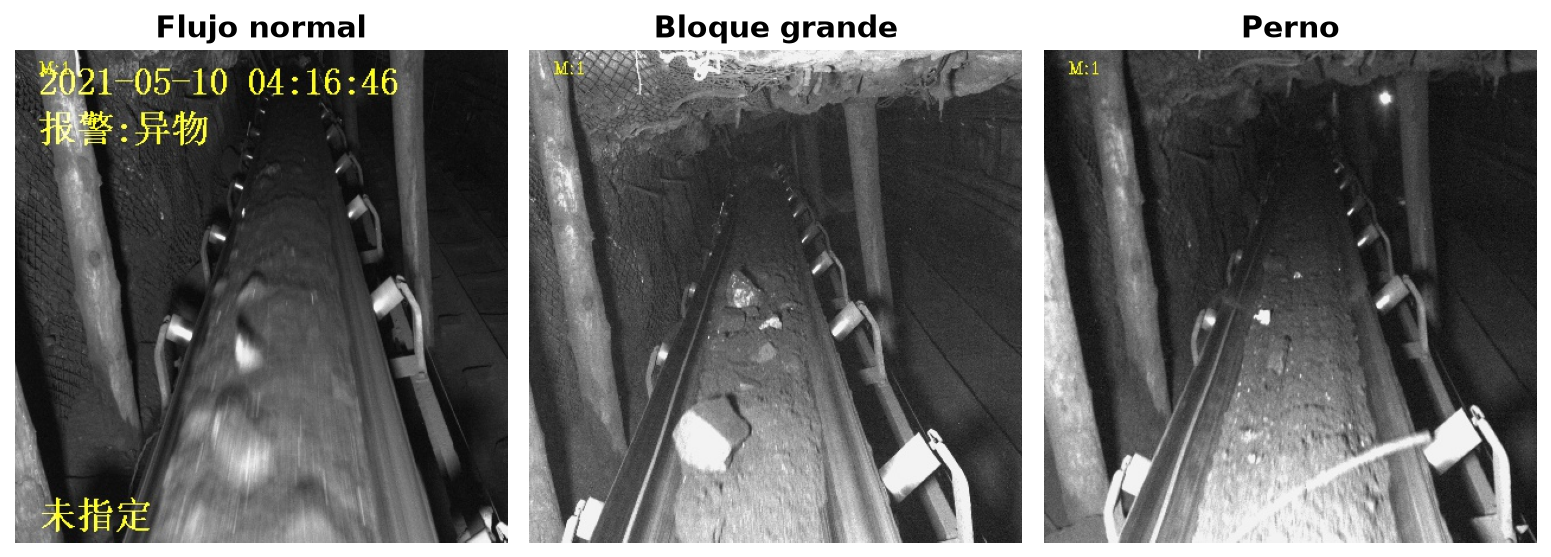

**Normal no significa «nada» ni cinta vacía.** El mineral normal también tiene rocas.

| Tipo de tarea | Qué entregaría | Lo implementamos |
|---|---|---|
| Clasificación | Una etiqueta para la foto completa | **Sí** |
| Detección de objetos | Etiqueta y rectángulo que ubica cada objeto | Después |
| Segmentación | Píxeles que pertenecen a cada objeto | Después |

Usamos etiquetas por foto, sin dibujar cajas.
La alerta normal/riesgo se calcula después con las probabilidades del **mismo clasificador**.

### Texto para decir

Nuestro proyecto busca reconocer condiciones de riesgo en imágenes de una cinta transportadora. En esta etapa entrenamos un solo modelo que clasifica cada foto en tres categorías: flujo normal, bloque grande o perno. Normal no significa que la cinta esté vacía: puede tener mineral circulando. Tampoco cualquier roca es un riesgo; el bloque grande es una categoría específica del dataset.

Esto es clasificación: damos una etiqueta a la imagen completa. Ubicar el objeto con un rectángulo sería detección, y señalar qué píxeles le pertenecen sería segmentación. Esas tareas quedan para después. Además de la etiqueta, usamos las probabilidades del mismo modelo para producir una alerta de riesgo. Por lo tanto, mostramos dos lecturas del mismo resultado, no dos modelos distintos.

## 2. Qué datos usamos y qué sacamos · 01:00–02:00

**Modelamos con carbón (`coal`). Hierro (`iron`) quedó explorado, pendiente de etiquetar por imagen.**

| Decisión sobre coal | Archivos | Por qué |
|---|---:|---|
| Inicio | 4.800 | Tres clases originales |
| Excluir imágenes idénticas con etiquetas contradictorias | −135 | La misma foto no debe enseñar clases distintas |
| Retirar copias adicionales con etiqueta consistente | −165 | Evitar contar varias veces el mismo contenido |
| **Conservar** | **4.500** | Imágenes únicas candidatas al modelado |

Se conservaron los originales. Las fotos oscuras y borrosas no se descartaron por ser difíciles.
Las imágenes parecidas se **agruparon al separar los datos**; no se eliminaron todas.

### Texto para decir

Revisamos dos conjuntos: uno de carbón, con cuatro mil ochocientas imágenes, y otro de hierro, con diecinueve mil doscientas once. Para modelar usamos carbón, porque ya tenía etiquetas por imagen. En hierro, el nombre de una carpeta no asegura que un objeto esté presente en cada foto.

Antes de entrenar retiramos ciento treinta y cinco archivos que repetían imágenes con etiquetas contradictorias. No elegimos una etiqueta al azar. También retiramos ciento sesenta y cinco copias repetidas que tenían etiquetas consistentes. Quedaron cuatro mil quinientas imágenes únicas. Conservamos los originales y no eliminamos automáticamente las fotos oscuras o borrosas, porque también representan dificultades reales del problema. Las imágenes parecidas se agruparon para reducir contaminación entre entrenamiento y evaluación.

## 3. El flujo que elegimos · 02:00–03:00

**Camino elegido: datos limpios → separación por grupos → texto ocultado y tamaño 224 × 224 → ResNet-18 → ajuste final.**

1. Reutilizar una red preentrenada: empezar con características visuales ya aprendidas.
2. Adaptar su salida a **normal, bloque grande y perno**.
3. Ajustar el último bloque y conservar la mejor época de validación.

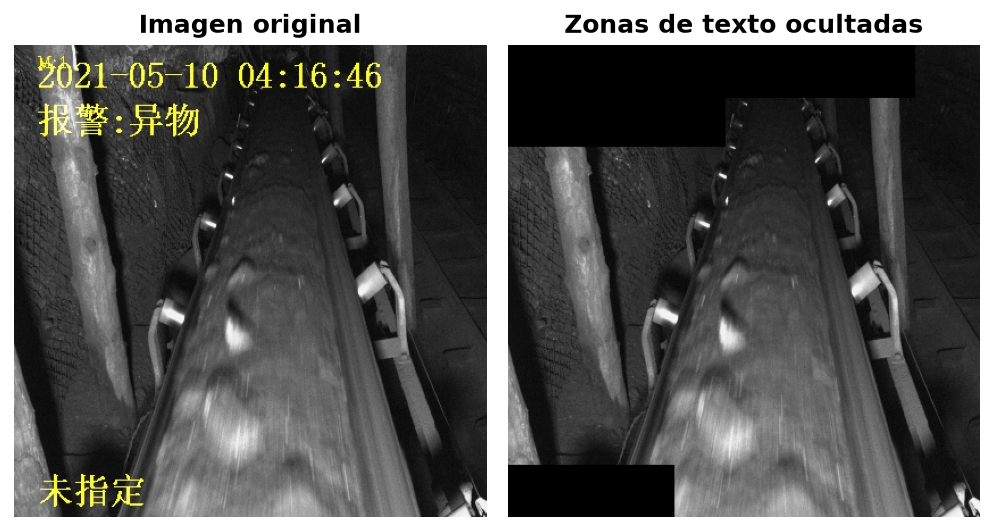

**Tapar texto es preprocesamiento, no detección ni segmentación.** La misma regla se aplicó a todas las clases.
También oculta parte de la escena: no atribuimos toda la diferencia de desempeño solo al texto.

### Texto para decir

El flujo elegido es simple. Primero limpiamos los datos y separamos los grupos. Después ocultamos las zonas del texto sobreimpreso, como fechas y mensajes de alarma, y ajustamos las imágenes a doscientos veinticuatro píxeles por lado. Buscamos que el modelo se apoye en la escena y no en un aviso de otro sistema.

Usamos ResNet dieciocho, una red preentrenada que ya aprendió características visuales de otras imágenes. Primero entrenamos su salida para nuestras tres categorías. Luego ajustamos su último bloque a estas cintas. Los rectángulos negros solo ocultan texto: no son detecciones ni segmentación. También borran parte de la escena, por lo que revisamos ejemplos y dejamos esa limitación documentada. Este es el camino del modelo que finalmente seleccionamos.

## 4. Cómo elegimos el modelo · 03:00–04:00

**Aprender, elegir y evaluar son etapas separadas.**

| Etapa | Imágenes | Para qué |
|---|---:|---|
| Entrenamiento | 3.211 | Aprender |
| Validación | 644 | Elegir el modelo y el umbral |
| Prueba final | 645 | Evaluar lo ya elegido |

| Comparación breve | Macro-F1 de validación |
|---|---:|
| Solo brillo, contraste y otras señales simples | 0.768 |
| Red preentrenada, imágenes originales, sin ajustar el bloque final | 0.904 |
| Red preentrenada, texto ocultado, sin ajustar el bloque final | 0.889 |
| **Texto ocultado + ajuste del último bloque: elegido** | **0.921** |

Macro-F1 combina precisión y capacidad de recuperar los casos de cada clase, con igual peso para las tres; 1 es mejor.
**No es el porcentaje de fotos correctas.** Ocultar texto por sí solo no mejoró esta comparación.
La mejor época del modelo elegido fue la **tercera**; seguir entrenando produjo sobreajuste.

### Texto para decir

Separamos tres grupos de datos con funciones distintas. El entrenamiento permite aprender. La validación permite comparar opciones. La prueba final se reserva para evaluar el modelo ya elegido. Usamos tres mil doscientas once imágenes para entrenar, seiscientas cuarenta y cuatro para validar y seiscientas cuarenta y cinco para la prueba.

La mejor opción de validación fue la red con texto ocultado y ajuste del último bloque: obtuvo un macro F uno de cero coma novecientos veintiuno. Este indicador da igual importancia a las tres clases. Conservamos la tercera época, porque seguir entrenando mejoraba el entrenamiento pero no la validación. Las variaciones adicionales de iluminación y tamaño no superaron esa opción. La elección se hizo antes de consultar la prueba final.

## 5. Resultados: etiqueta y alerta · 04:00–05:00

**Lectura 1 · clasificación de tres etiquetas**

| Etiqueta del dataset | Casos clasificados correctamente en prueba |
|---|---:|
| Normal | 196 / 212 |
| Bloque grande | 206 / 217 |
| Perno | 199 / 216 |
| **Total** | **601 / 645 · 93.2%** |

**Macro-F1 de prueba: 0.932.**

**Lectura 2 · alerta derivada: normal/riesgo**

Sumamos las probabilidades de **bloque grande + perno** y las comparamos con un umbral elegido en validación para priorizar la sensibilidad.

| Resultado de alarma, según las etiquetas del dataset | Prueba final |
|---|---:|
| Riesgos con alerta | **432 / 433 · 99.8%** |
| Riesgos omitidos | **1** |
| Imágenes normales con falsa alarma | **24 / 212 · 11.3%** |

**Son dos decisiones sobre el mismo modelo.** Confundir bloque y perno puede ser un error de clase sin perder la alerta.
La alerta tiene su propio umbral conservador: incluso una foto cuya clase más probable sea normal puede activar alarma.

### Texto para decir

En la prueba final, el modelo asignó correctamente la etiqueta a seiscientas una de seiscientas cuarenta y cinco imágenes: aproximadamente noventa y tres por ciento. El macro F uno fue cero coma novecientos treinta y dos.

Para la alerta sumamos las probabilidades de bloque grande y perno, y las comparamos con un umbral elegido en validación para priorizar la detección de riesgos. No entrenamos otra red. Esta regla detectó cuatrocientas treinta y dos de cuatrocientas treinta y tres imágenes etiquetadas como riesgo, pero generó veinticuatro falsas alarmas entre doscientas doce imágenes normales. Eso equivale a un once coma tres por ciento de falsas alarmas. Confundir un bloque con un perno puede ser un error de etiqueta y aun activar correctamente la alerta: son dos formas distintas de evaluar el mismo modelo.

## 6. Qué aprendimos y qué sigue · 05:00–06:00

**Aprendizajes para exponer**

- Limpiar etiquetas y duplicados fue una parte esencial del modelado.
- Ajustar el último bloque ayudó; más entrenamiento, más tamaño o variaciones de luz no garantizaron mejoras.
- Los pernos finos, la oscuridad y las etiquetas dudosas siguen siendo dificultades.
- Detectar casi todos los riesgos no basta: **11,3% de falsas alarmas por imagen normal sigue siendo importante**.

**Alcance:** evaluación interna, etiquetas heredadas y agrupación aproximada de eventos; una semilla por configuración.
No demuestra rendimiento en otra planta ni permite calcular alarmas por hora. La frecuencia de riesgos en planta también puede cambiar la precisión de las alarmas.

**Siguiente paso:** revisar etiquetas dudosas y anotar una muestra de iron; después comparar modelos separados frente a uno conjunto.
Las cajas se necesitan para la futura localización; los sintéticos se evaluarían después sobre imágenes reales.

### Texto para decir

El principal aprendizaje es que preparar bien los datos importa tanto como elegir la red. Encontramos duplicados, etiquetas contradictorias y texto que podía servir como atajo. Ajustar parte de una red preentrenada mejoró la clasificación, pero seguir entrenando produjo sobreajuste.

Todavía hay dificultades con pernos delgados, escenas oscuras y algunas etiquetas discutibles. Además, una alta detección de riesgos no elimina el problema de las falsas alarmas. Estos resultados corresponden a una evaluación interna, con agrupaciones aproximadas de eventos; no prueban funcionamiento en otra planta. El siguiente paso es revisar las etiquetas dudosas y etiquetar una muestra de hierro. Después podremos evaluar si conviene combinar los datasets. Las cajas, la segmentación y los datos sintéticos quedan para experimentos posteriores, según lo que necesitemos resolver.

## Apoyo técnico · fuera del video

- El modelo asigna una sola clase por foto; no cuenta objetos ni devuelve ubicaciones.
- La regla de alarma usa probabilidad de bloque + probabilidad de perno ≥ **0.019967**.
  Ese umbral se eligió con validación maximizando F2, que da más peso a no omitir riesgos. No se ajustó con la prueba final.
- 432/433 mide sensibilidad de alarma. 601/645 mide acierto de la etiqueta. Son objetivos y denominadores diferentes.
- Las clases de referencia proceden de las carpetas: requieren revisión adicional; «bloque grande» no estima centímetros.
- El detalle, los experimentos y la reproducción permanecen en [la v1](entrega_modelado.ipynb) y el [README](README.md).

**Comprobación opcional:** la única celda de código está al final, oculta por defecto.
Lee los resultados locales y verifica las cifras; no entrena ni cambia la selección.

In [1]:
from pathlib import Path
import json, csv, hashlib

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data/results/patrick_v1/final_test.json').exists())
results = root / 'data/results/patrick_v1'
final = json.loads((results / 'final_test.json').read_text())
with (results / 'runs' / final['selection']['run'] / 'test_predictions.csv').open() as f:
    predictions = list(csv.DictReader(f))
correct = sum(int(r['target']) == int(r['prediction']) for r in predictions)
threshold = final['selection']['risk_threshold']
tp = sum(int(r['target']) != 0 and float(r['p1']) + float(r['p2']) >= threshold for r in predictions)
fp = sum(int(r['target']) == 0 and float(r['p1']) + float(r['p2']) >= threshold for r in predictions)
assert len(predictions) == 645 and correct == 601
assert tp == final['test']['risk']['tp'] == 432
assert fp == final['test']['risk']['fp'] == 24
checkpoint = root / 'data/weights/patrick_v1' / (final['selection']['run'] + '.pt')
assert hashlib.sha256(checkpoint.read_bytes()).hexdigest() == final['selection']['weights_sha256']
print('Cifras verificadas: 601/645 etiquetas correctas; 432/433 riesgos con alerta; 24/212 falsas alarmas.')
print('Mismos resultados de v1; no se reentrenó ni se modificó el modelo.')

Cifras verificadas: 601/645 etiquetas correctas; 432/433 riesgos con alerta; 24/212 falsas alarmas.
Mismos resultados de v1; no se reentrenó ni se modificó el modelo.
